# Machine Learning Engineering Hands-On — Lab Series 01

**Based on the supplied lab guide.**

This notebook implements all five required exercises end-to-end:

1. Multiple Linear Regression — Insurance Cost Prediction
2. Logistic Regression — Bank Marketing Conversion
3. Decision Trees — Interpretable Churn / Rule Mining
4. Random Forests — Ensemble Bagging & Feature Importance
5. K-Means — Wholesale Spending Personas

It also creates the required submission artifacts:

- `exercise1_insurance_predictions.csv`
- `exercise2_bank_predictions.csv`
- `exercise3_decision_tree_predictions.csv`
- `exercise4_random_forest_predictions.csv`
- `exercise5_wholesale_clusters.csv`
- `executive_diagnostic_brief.pdf`

The notebook is designed for **Google Colab** and uses reproducible `random_state=42` settings where applicable.


## 0. Environment check

The guide specifies **Python 3.12 + Scikit-Learn** and requires a clean notebook that runs top-to-bottom without runtime errors. fileciteturn0file0L2-L4

Run this cell first. If Colab shows a Python version different from the guide, the notebook still records the environment so the submission is auditable.


In [1]:
import sys, platform, sklearn, pandas as pd, numpy as np, matplotlib, seaborn as sns
print("Python:", sys.version)
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
pandas: 2.2.3
numpy: 2.1.3
scikit-learn: 1.6.1
matplotlib: 3.10.0


In [2]:
# Install only the lightweight UCI helper if it is not already available.
# The notebook primarily uses direct public dataset downloads and does not require Kaggle credentials.
import importlib.util, subprocess, sys

if importlib.util.find_spec("ucimlrepo") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])

print("Environment ready.")


Environment ready.


## 1. Download and cache the datasets

The lab guide specifies the Medical Cost Personal Data, UCI Bank Marketing, and UCI Wholesale Customers datasets. fileciteturn0file0L40-L48 fileciteturn0file0L118-L126 fileciteturn0file0L233-L240

The Bank Marketing and Wholesale Customers datasets are maintained by the UCI Machine Learning Repository. urlUCI Bank Marketinghttps://archive.ics.uci.edu/dataset/222/bank%2Bmarketing urlUCI Wholesale Customershttps://archive.ics.uci.edu/dataset/292/wholesale%2Bcustomers

For the insurance dataset, the notebook uses a public copy with the exact seven columns required by the guide.


In [3]:
from pathlib import Path
import io, zipfile, urllib.request, shutil, os, json, warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path("/content/ml_lab_data")
OUT_DIR = Path("/content/ml_lab_outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

def download(url, destination):
    destination = Path(destination)
    if not destination.exists():
        urllib.request.urlretrieve(url, destination)
    return destination

# 1) Insurance / Medical Cost Personal Dataset
insurance_url = "https://raw.githubusercontent.com/pycaret/datasets/main/data/common/insurance.csv"
insurance_path = DATA_DIR / "insurance.csv"
download(insurance_url, insurance_path)

# 2) UCI Bank Marketing
# UCI's current archive contains bank.zip and bank-additional.zip inside
# bank+marketing.zip. The full dataset is inside the nested bank.zip archive.
bank_outer = DATA_DIR / "bank_marketing.zip"
download("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip", bank_outer)

bank_path = DATA_DIR / "bank-full.csv"

with zipfile.ZipFile(bank_outer) as outer:
    names = outer.namelist()
    nested_bank = next((m for m in names if m.endswith("bank.zip")), None)

    if nested_bank:
        nested_bytes = outer.read(nested_bank)
        with zipfile.ZipFile(io.BytesIO(nested_bytes)) as inner:
            inner_names = inner.namelist()
            bank_member = next(
                (m for m in inner_names if m.endswith("bank-full.csv")),
                None
            )
            if bank_member is None:
                raise FileNotFoundError(
                    f"bank-full.csv not found inside nested bank.zip. "
                    f"Available files: {inner_names}"
                )
            with inner.open(bank_member) as src, open(bank_path, "wb") as dst:
                shutil.copyfileobj(src, dst)
    else:
        # Fallback in case UCI changes the archive structure again.
        bank_member = next(
            (m for m in names if m.endswith("bank-full.csv")),
            None
        )
        if bank_member is None:
            raise FileNotFoundError(
                f"Could not find bank-full.csv. Archive contents: {names}"
            )
        with outer.open(bank_member) as src, open(bank_path, "wb") as dst:
            shutil.copyfileobj(src, dst)

# 3) UCI Wholesale Customers
wholesale_zip_path = DATA_DIR / "wholesale_customers.zip"
download(
    "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip",
    wholesale_zip_path
)

wholesale_path = DATA_DIR / "Wholesale customers data.csv"

with zipfile.ZipFile(wholesale_zip_path) as z:
    members = z.namelist()
    wholesale_member = next(
        (m for m in members if m.endswith("Wholesale customers data.csv")),
        None
    )
    if wholesale_member is None:
        raise FileNotFoundError(
            f"Could not find Wholesale customers data.csv. Archive contents: {members}"
        )
    with z.open(wholesale_member) as src, open(wholesale_path, "wb") as dst:
        shutil.copyfileobj(src, dst)

print("Datasets ready:")
for p in [insurance_path, bank_path, wholesale_path]:
    print(" -", p, f"({p.stat().st_size:,} bytes)")

print("\nBank dataset preview:")
import pandas as pd
display(pd.read_csv(bank_path, sep=";").head())


Datasets ready:
 - /content/ml_lab_data/insurance.csv (54,289 bytes)
 - /content/ml_lab_data/bank-full.csv (4,610,348 bytes)
 - /content/ml_lab_data/Wholesale customers data.csv (15,021 bytes)

Bank dataset preview:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# Exercise 1 — Multiple Linear Regression: Insurance Cost Prediction

The guide requires an 80/20 split with `random_state=42`, numeric scaling, one-hot encoding with `drop='first'`, LinearRegression, RMSE/R² evaluation, coefficient inspection, and residual diagnostics. The target benchmark is **R² ≥ 0.75 and RMSE < $4,800**. fileciteturn0file0L60-L68 fileciteturn0file0L96-L100


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import skew

insurance = pd.read_csv(insurance_path)
insurance.columns = [c.strip() for c in insurance.columns]

required_cols = ['age','sex','bmi','children','smoker','region','charges']
missing = [c for c in required_cols if c not in insurance.columns]
assert not missing, f"Missing insurance columns: {missing}"

print("Shape:", insurance.shape)
display(insurance.head())
print("\nMissing values:")
display(insurance.isna().sum().to_frame("missing"))
print("\nCharges skewness:", round(skew(insurance["charges"]), 3))


Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Missing values:


,missing
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0



Charges skewness: 1.514


In [5]:
# Raw-target vs log1p-target benchmark
num_cols = ['age', 'bmi', 'children']
cat_cols = ['sex', 'smoker', 'region']

X = insurance.drop(columns='charges')
y = insurance['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

raw_pipeline = Pipeline(steps=[
    ('prep', preprocessor),
    ('regressor', LinearRegression())
])
raw_pipeline.fit(X_train, y_train)
raw_pred = raw_pipeline.predict(X_test)

raw_rmse = np.sqrt(mean_squared_error(y_test, raw_pred))
raw_r2 = r2_score(y_test, raw_pred)

# Log-target benchmark; predictions are transformed back for fair RMSE/R² comparison.
log_pipeline = Pipeline(steps=[
    ('prep', preprocessor),
    ('regressor', LinearRegression())
])
log_pipeline.fit(X_train, np.log1p(y_train))
log_pred = np.expm1(log_pipeline.predict(X_test))

log_rmse = np.sqrt(mean_squared_error(y_test, log_pred))
log_r2 = r2_score(y_test, log_pred)

insurance_benchmark = pd.DataFrame({
    "Model": ["Linear Regression — raw target", "Linear Regression — log1p target"],
    "RMSE": [raw_rmse, log_rmse],
    "R2": [raw_r2, log_r2]
})
display(insurance_benchmark)

print(f"Raw target -> R²={raw_r2:.4f}, RMSE=${raw_rmse:,.2f}")
print(f"log1p target -> R²={log_r2:.4f}, RMSE=${log_rmse:,.2f}")


,Model,RMSE,R2
0,Linear Regression — raw target,5796.284659,0.783593
1,Linear Regression — log1p target,7814.064026,0.606698


Raw target -> R²=0.7836, RMSE=$5,796.28
log1p target -> R²=0.6067, RMSE=$7,814.06


In [6]:
# Inspect learned coefficients from the raw model.
feature_names = raw_pipeline.named_steps['prep'].get_feature_names_out()
coefs = raw_pipeline.named_steps['regressor'].coef_

coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefs
}).sort_values("coefficient", ascending=False)

display(coef_table)

smoker_rows = coef_table[coef_table["feature"].str.contains("smoker_yes", regex=False)]
print("Smoker coefficient(s):")
display(smoker_rows)


,feature,coefficient
4,cat__smoker_yes,23651.128856
0,num__age,3614.975415
1,num__bmi,2036.228123
2,num__children,516.890247
3,cat__sex_male,-18.591692
5,cat__region_northwest,-370.677326
6,cat__region_southeast,-657.864297
7,cat__region_southwest,-809.799354


Smoker coefficient(s):


,feature,coefficient
4,cat__smoker_yes,23651.128856


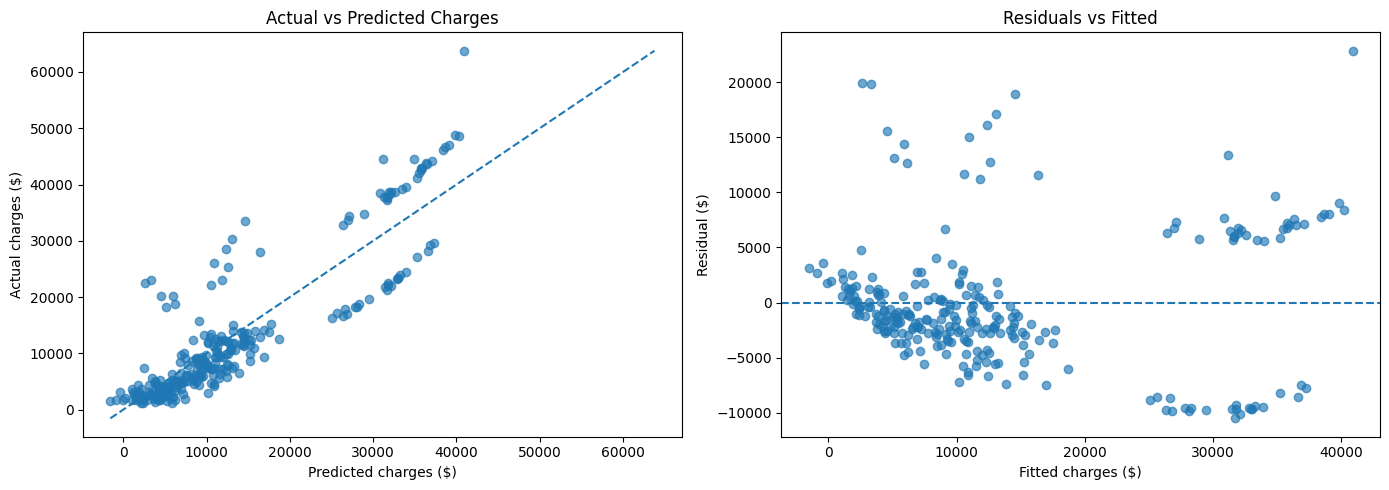

Exercise 1 artifact saved.


In [7]:
# Diagnostic plots required by the guide.
residuals = y_test.to_numpy() - raw_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(raw_pred, y_test, alpha=0.65)
lo = min(y_test.min(), raw_pred.min())
hi = max(y_test.max(), raw_pred.max())
axes[0].plot([lo, hi], [lo, hi], linestyle="--")
axes[0].set_title("Actual vs Predicted Charges")
axes[0].set_xlabel("Predicted charges ($)")
axes[0].set_ylabel("Actual charges ($)")

axes[1].scatter(raw_pred, residuals, alpha=0.65)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs Fitted")
axes[1].set_xlabel("Fitted charges ($)")
axes[1].set_ylabel("Residual ($)")

plt.tight_layout()
plt.show()

insurance_pred = X_test.copy()
insurance_pred["actual_charges"] = y_test.values
insurance_pred["predicted_charges"] = raw_pred
insurance_pred["residual"] = residuals
insurance_pred.to_csv(OUT_DIR / "exercise1_insurance_predictions.csv", index=False)

print("Exercise 1 artifact saved.")


### Exercise 1 interpretation

The guide specifically asks the diagnostic report to discuss the fan-out of residual variance at higher expense tiers and the possible mitigation from log transformation. fileciteturn0file0L96-L100

Do not claim a benchmark is met until the printed values above are checked.


# Exercises 2–4 shared Bank Marketing dataset

The guide describes an approximately 11.7% positive conversion rate and requires stratified splitting, class weighting, threshold calibration, interpretable decision trees, pruning, Random Forest OOB validation, GridSearchCV, and feature importance. fileciteturn0file0L112-L134 fileciteturn0file0L167-L176 fileciteturn0file0L192-L203


In [8]:
bank = pd.read_csv(bank_path, sep=';')
bank.columns = [c.strip() for c in bank.columns]

assert "y" in bank.columns, "Bank dataset must contain target column y."
bank["target"] = bank["y"].map({"no": 0, "yes": 1}).astype(int)

print("Shape:", bank.shape)
print("Positive rate:", round(bank["target"].mean(), 4))
display(bank.head())

print("\nMissing values:")
display(bank.isna().sum().to_frame("missing").query("missing > 0"))


Shape: (45211, 18)
Positive rate: 0.117


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,target
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0



Missing values:


,missing


## Exercise 2 — Logistic Regression

The guide calls for RobustScaler on `balance` and `duration`, OneHotEncoder for categoricals, `class_weight='balanced'`, `max_iter=1000`, and a decision threshold of **0.35**. The acceptance target is **ROC-AUC ≥ 0.78 and Recall ≥ 0.70**. fileciteturn0file0L128-L154


In [9]:
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    precision_recall_curve, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression

# Use the fields explicitly highlighted in the lab guide for Exercise 2.
ex2_num = ['age', 'balance', 'duration', 'campaign']
ex2_cat = ['job', 'poutcome']

X2 = bank[ex2_num + ex2_cat].copy()
y2 = bank["target"].copy()

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.25, random_state=42, stratify=y2
)

prep2 = ColumnTransformer(transformers=[
    ('num', RobustScaler(), ['balance', 'duration']),
    ('num_standard', StandardScaler(), ['age', 'campaign']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ex2_cat)
])

log_reg = Pipeline(steps=[
    ('prep', prep2),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        solver='lbfgs',
        random_state=42
    ))
])

log_reg.fit(X2_train, y2_train)
y2_probs = log_reg.predict_proba(X2_test)[:, 1]
threshold = 0.35
y2_pred = (y2_probs >= threshold).astype(int)

auc2 = roc_auc_score(y2_test, y2_probs)
recall2 = recall_score(y2_test, y2_pred)
precision2 = precision_score(y2_test, y2_pred)
f12 = f1_score(y2_test, y2_pred)

print(f"ROC-AUC: {auc2:.4f}")
print(f"Threshold: {threshold:.2f}")
print(f"Precision: {precision2:.4f}")
print(f"Recall: {recall2:.4f}")
print(f"F1: {f12:.4f}")
print("\nClassification report:")
print(classification_report(y2_test, y2_pred, target_names=["No Deposit", "Subscribed"]))

cm2 = confusion_matrix(y2_test, y2_pred)
print("Confusion matrix:")
display(pd.DataFrame(cm2, index=["Actual No", "Actual Yes"], columns=["Pred No", "Pred Yes"]))


ROC-AUC: 0.8645
Threshold: 0.35
Precision: 0.2745
Recall: 0.8487
F1: 0.4149

Classification report:
              precision    recall  f1-score   support

  No Deposit       0.97      0.70      0.82      9981
  Subscribed       0.27      0.85      0.41      1322

    accuracy                           0.72     11303
   macro avg       0.62      0.78      0.62     11303
weighted avg       0.89      0.72      0.77     11303

Confusion matrix:


,Pred No,Pred Yes
Actual No,7016,2965
Actual Yes,200,1122


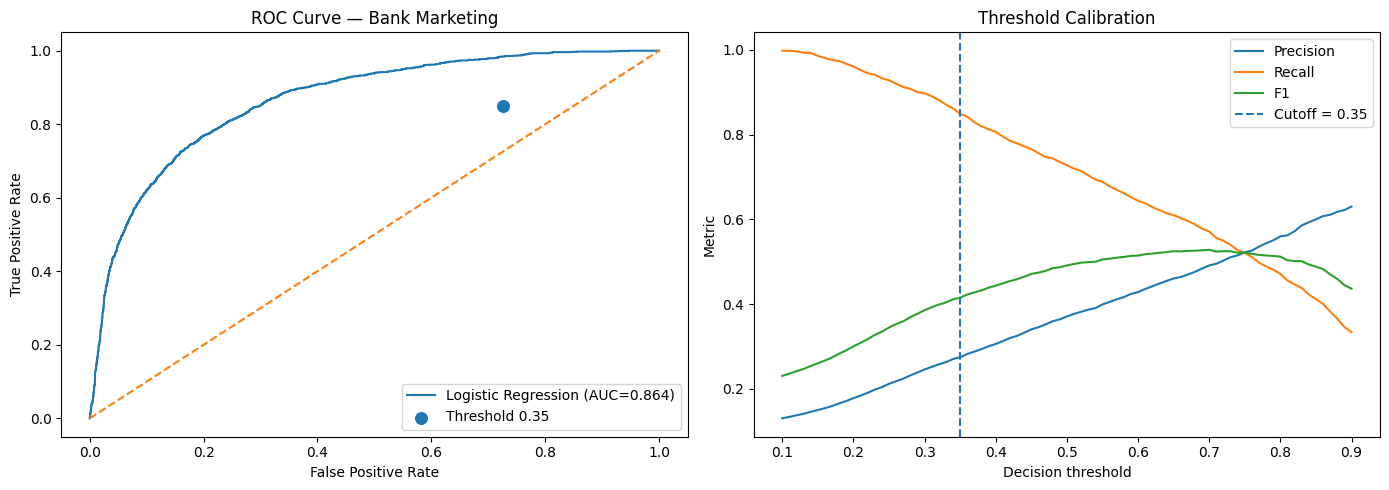

In [10]:
# ROC and Precision-Recall / threshold trade-off plots.
fpr, tpr, roc_thresholds = roc_curve(y2_test, y2_probs)
precisions, recalls, pr_thresholds = precision_recall_curve(y2_test, y2_probs)

threshold_grid = np.linspace(0.10, 0.90, 81)
threshold_rows = []
for t in threshold_grid:
    pred_t = (y2_probs >= t).astype(int)
    threshold_rows.append({
        "threshold": t,
        "precision": precision_score(y2_test, pred_t, zero_division=0),
        "recall": recall_score(y2_test, pred_t, zero_division=0),
        "f1": f1_score(y2_test, pred_t, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(fpr, tpr, label=f"Logistic Regression (AUC={auc2:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--")
axes[0].scatter(
    [(1 - precision2)], [recall2],
    s=70, label="Threshold 0.35"
)
axes[0].set_title("ROC Curve — Bank Marketing")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
axes[1].plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
axes[1].plot(threshold_df["threshold"], threshold_df["f1"], label="F1")
axes[1].axvline(threshold, linestyle="--", label="Cutoff = 0.35")
axes[1].set_title("Threshold Calibration")
axes[1].set_xlabel("Decision threshold")
axes[1].set_ylabel("Metric")
axes[1].legend()

plt.tight_layout()
plt.show()

bank_pred2 = X2_test.copy()
bank_pred2["actual"] = y2_test.values
bank_pred2["prob_subscribed"] = y2_probs
bank_pred2["predicted"] = y2_pred
bank_pred2.to_csv(OUT_DIR / "exercise2_bank_predictions.csv", index=False)


## Exercise 3 — Decision Trees

The guide requires comparison of Gini vs entropy, an unconstrained overfitting demonstration, constrained hyperparameters, cost-complexity pruning, and extraction of human-readable rules. The acceptance target is **test accuracy ≥ 85% with depth ≤ 5**. fileciteturn0file0L167-L187


In [11]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_score

# For Exercises 3–4 use the full bank feature set except the original target columns.
drop_cols = ["y", "target"]
X34 = bank.drop(columns=drop_cols).copy()
y34 = bank["target"].copy()

X34_train, X34_test, y34_train, y34_test = train_test_split(
    X34, y34, test_size=0.25, random_state=42, stratify=y34
)

num34 = X34_train.select_dtypes(include=np.number).columns.tolist()
cat34 = X34_train.select_dtypes(exclude=np.number).columns.tolist()

prep34 = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num34),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat34)
])

X34_train_prep = prep34.fit_transform(X34_train)
X34_test_prep = prep34.transform(X34_test)
feature_names34 = prep34.get_feature_names_out()

# Gini vs entropy comparison
criteria_rows = []
for criterion in ["gini", "entropy"]:
    clf = DecisionTreeClassifier(criterion=criterion, random_state=42)
    clf.fit(X34_train_prep, y34_train)
    criteria_rows.append({
        "criterion": criterion,
        "depth": clf.get_depth(),
        "train_accuracy": clf.score(X34_train_prep, y34_train),
        "test_accuracy": clf.score(X34_test_prep, y34_test)
    })
display(pd.DataFrame(criteria_rows))

# Unconstrained tree for overfitting demonstration
unconstrained = DecisionTreeClassifier(random_state=42)
unconstrained.fit(X34_train_prep, y34_train)
print("Unconstrained tree:")
print("Depth:", unconstrained.get_depth())
print("Train accuracy:", round(unconstrained.score(X34_train_prep, y34_train), 4))
print("Test accuracy:", round(unconstrained.score(X34_test_prep, y34_test), 4))


,criterion,depth,train_accuracy,test_accuracy
0,gini,40,1.0,0.877289
1,entropy,40,1.0,0.874635


Unconstrained tree:
Depth: 40
Train accuracy: 1.0
Test accuracy: 0.8773


In [12]:
# Constrained tree and cost-complexity pruning.
base_tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)
base_tree.fit(X34_train_prep, y34_train)

path = base_tree.cost_complexity_pruning_path(X34_train_prep, y34_train)
alphas = np.unique(path.ccp_alphas)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
alpha_results = []

for alpha in alphas:
    candidate = DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=10,
        ccp_alpha=float(alpha),
        random_state=42
    )
    scores = cross_val_score(candidate, X34_train_prep, y34_train, cv=cv, scoring="accuracy", n_jobs=-1)
    candidate.fit(X34_train_prep, y34_train)
    # Keep only trees satisfying the required depth <= 5.
    if candidate.get_depth() <= 5:
        alpha_results.append({
            "ccp_alpha": float(alpha),
            "cv_accuracy_mean": scores.mean(),
            "cv_accuracy_std": scores.std(),
            "depth": candidate.get_depth()
        })

alpha_results_df = pd.DataFrame(alpha_results).sort_values(
    ["cv_accuracy_mean", "depth"], ascending=[False, True]
)
display(alpha_results_df.head(10))

best_alpha = float(alpha_results_df.iloc[0]["ccp_alpha"])
dt_clf = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    ccp_alpha=best_alpha,
    random_state=42
)
dt_clf.fit(X34_train_prep, y34_train)

dt_acc = dt_clf.score(X34_test_prep, y34_test)
print(f"Selected ccp_alpha: {best_alpha:.8f}")
print(f"Pruned depth: {dt_clf.get_depth()}")
print(f"Test accuracy: {dt_acc:.4f}")

rules = export_text(
    dt_clf,
    feature_names=list(feature_names34),
    max_depth=3
)
print("\n--- Extracted decision rules ---\n")
print(rules[:5000])


,ccp_alpha,cv_accuracy_mean,cv_accuracy_std,depth
9,0.000124,0.901056,0.002075,5
10,0.000140,0.901056,0.002131,5
11,0.000167,0.901056,0.002293,5
6,0.000093,0.900938,0.001842,5
7,0.000099,0.900879,0.001916,5
8,0.000100,0.900879,0.001916,5
12,0.000189,0.900849,0.002248,5
13,0.000190,0.900849,0.002248,5
20,0.000972,0.900820,0.003049,5
19,0.000775,0.900761,0.002989,5


Selected ccp_alpha: 0.00012361
Pruned depth: 5
Test accuracy: 0.8992

--- Extracted decision rules ---

|--- num__duration <= 1.02
|   |--- cat__poutcome_success <= 0.50
|   |   |--- num__age <= 1.84
|   |   |   |--- num__duration <= 0.01
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__duration >  0.01
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- num__age >  1.84
|   |   |   |--- num__duration <= -0.51
|   |   |   |   |--- class: 0
|   |   |   |--- num__duration >  -0.51
|   |   |   |   |--- truncated branch of depth 2
|   |--- cat__poutcome_success >  0.50
|   |   |--- num__duration <= -0.49
|   |   |   |--- class: 0
|   |   |--- num__duration >  -0.49
|   |   |   |--- cat__month_may <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- cat__month_may >  0.50
|   |   |   |   |--- truncated branch of depth 2
|--- num__duration >  1.02
|   |--- num__duration <= 2.20
|   |   |--- cat__poutcome_success <= 0.50
|   |   |   |--- ca

In [13]:
# Save Exercise 3 predictions.
dt_probs = dt_clf.predict_proba(X34_test_prep)[:, 1]
dt_pred = (dt_probs >= 0.50).astype(int)

dt_output = X34_test.copy()
dt_output["actual"] = y34_test.values
dt_output["prob_subscribed"] = dt_probs
dt_output["predicted"] = dt_pred
dt_output.to_csv(OUT_DIR / "exercise3_decision_tree_predictions.csv", index=False)

print("Exercise 3 artifact saved.")


Exercise 3 artifact saved.


## Exercise 4 — Random Forests

The guide requires OOB validation, GridSearchCV over `n_estimators=[100,200]`, `max_features=['sqrt','log2']`, and `max_depth=[8,12]`, followed by MDI and permutation importance. The target is **OOB ≥ 0.88 and F1 ≥ 0.65**. fileciteturn0file0L192-L215


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

rf_baseline = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)
rf_baseline.fit(X34_train_prep, y34_train)

rf_baseline_oob = rf_baseline.oob_score_
rf_baseline_acc = rf_baseline.score(X34_test_prep, y34_test)
rf_baseline_pred = rf_baseline.predict(X34_test_prep)
rf_baseline_f1 = f1_score(y34_test, rf_baseline_pred)

print(f"Baseline OOB Score: {rf_baseline_oob:.4f}")
print(f"Baseline Test Accuracy: {rf_baseline_acc:.4f}")
print(f"Baseline Test F1: {rf_baseline_f1:.4f}")


Baseline OOB Score: 0.9046
Baseline Test Accuracy: 0.9065
Baseline Test F1: 0.4993


In [15]:
# Required grid search.
rf = RandomForestClassifier(
    oob_score=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_features": ["sqrt", "log2"],
    "max_depth": [8, 12]
}

grid = GridSearchCV(
    rf,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)
grid.fit(X34_train_prep, y34_train)

best_rf = grid.best_estimator_
rf_pred = best_rf.predict(X34_test_prep)
rf_f1 = f1_score(y34_test, rf_pred)
rf_acc = best_rf.score(X34_test_prep, y34_test)
rf_oob = best_rf.oob_score_

print("Best parameters:", grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.4f}")
print(f"OOB Score: {rf_oob:.4f}")
print(f"Test Accuracy: {rf_acc:.4f}")
print(f"Test F1: {rf_f1:.4f}")


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'max_depth': 12, 'max_features': 'sqrt', 'n_estimators': 200}
Best CV F1: 0.3536
OOB Score: 0.9004
Test Accuracy: 0.9016
Test F1: 0.3675


,feature,importance
3,num__duration,0.343296
49,cat__poutcome_success,0.099645
0,num__age,0.063520
1,num__balance,0.045916
5,num__pdays,0.045786
2,num__day,0.043230
6,num__previous,0.023896
29,cat__housing_yes,0.023092
4,num__campaign,0.019449
42,cat__month_mar,0.019419


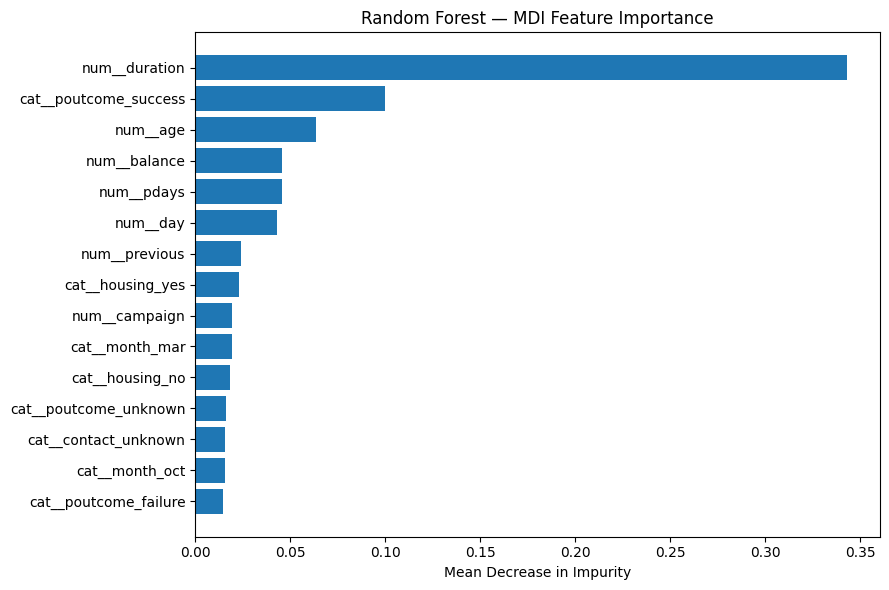

Top permutation features:


,feature,importance_mean,importance_std
49,cat__poutcome_success,0.181420,0.006909
3,num__duration,0.151187,0.019263
5,num__pdays,0.046513,0.006443
6,num__previous,0.024049,0.012322
42,cat__month_mar,0.022062,0.004660
34,cat__contact_unknown,0.014170,0.005288
28,cat__housing_no,0.014057,0.011550
4,num__campaign,0.012289,0.005903
50,cat__poutcome_unknown,0.012175,0.008242
31,cat__loan_yes,0.008654,0.002968


In [16]:
# MDI feature importance.
mdi = pd.DataFrame({
    "feature": feature_names34,
    "importance": best_rf.feature_importances_
}).sort_values("importance", ascending=False)

display(mdi.head(15))

plt.figure(figsize=(9, 6))
top_mdi = mdi.head(15).sort_values("importance")
plt.barh(top_mdi["feature"], top_mdi["importance"])
plt.title("Random Forest — MDI Feature Importance")
plt.xlabel("Mean Decrease in Impurity")
plt.tight_layout()
plt.show()

# Permutation importance on a manageable test sample.
sample_n = min(2500, X34_test_prep.shape[0])
rng = np.random.RandomState(42)
sample_idx = rng.choice(X34_test_prep.shape[0], size=sample_n, replace=False)

perm = permutation_importance(
    best_rf,
    X34_test_prep[sample_idx],
    y34_test.iloc[sample_idx],
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": feature_names34,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

print("Top permutation features:")
display(perm_df.head(15))


In [17]:
# Comparative benchmark required by the guide.
log_f1_common = f1_score(y34_test, (log_reg.predict_proba(X2_test)[:,1] >= 0.35).astype(int))

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Test F1": [log_f1_common, f1_score(y34_test, dt_pred), rf_f1]
}).sort_values("Test F1", ascending=False)

display(comparison)

rf_output = X34_test.copy()
rf_output["actual"] = y34_test.values
rf_output["predicted"] = rf_pred
rf_output["prob_subscribed"] = best_rf.predict_proba(X34_test_prep)[:, 1]
rf_output.to_csv(OUT_DIR / "exercise4_random_forest_predictions.csv", index=False)

print("Exercise 4 artifact saved.")


,Model,Test F1
1,Decision Tree,0.430215
0,Logistic Regression,0.414864
2,Random Forest,0.367463


Exercise 4 artifact saved.


# Exercise 5 — K-Means Clustering: Wholesale Spending Personas

The guide requires `log1p()` followed by StandardScaler, an elbow search from k=2 to 8, silhouette analysis, k=4 clustering, unscaled centroid profiling, and four actionable commercial personas. fileciteturn0file0L227-L257


,k,inertia
0,2,1844.064069
1,3,1553.412722
2,4,1386.862741
3,5,1266.149362
4,6,1174.536397
5,7,1086.358700
6,8,1024.046798


,k,silhouette
0,2,0.290328
1,3,0.258278
2,4,0.188495
3,5,0.191585
4,6,0.195319
5,7,0.195780
6,8,0.191491


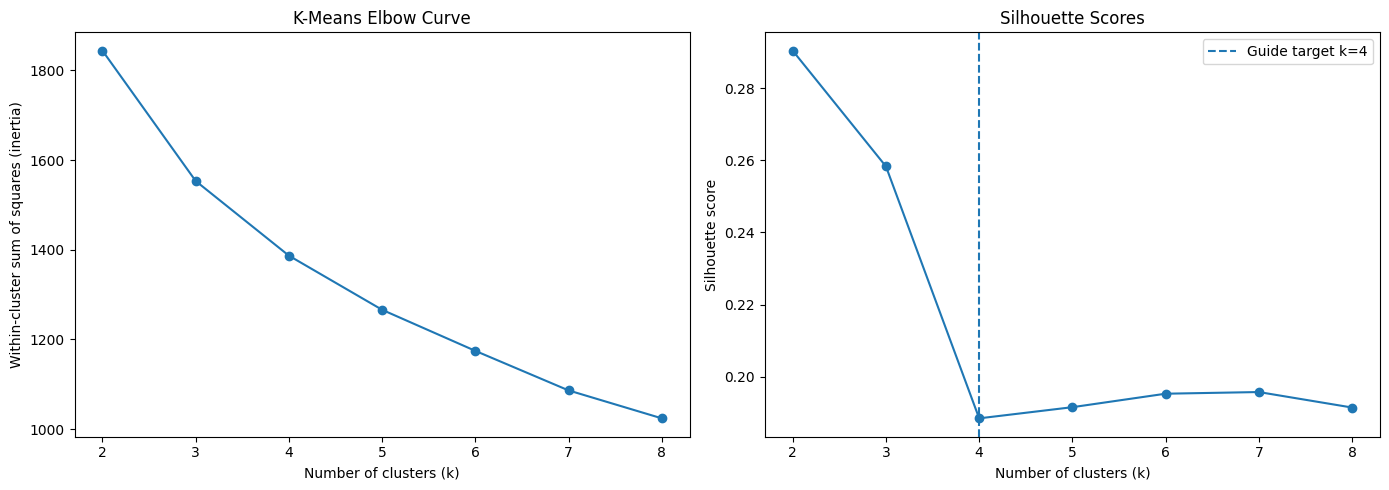

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wholesale = pd.read_csv(wholesale_path)

# UCI file uses these six spending fields.
spend_cols = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicassen"
]
missing_w = [c for c in spend_cols if c not in wholesale.columns]
assert not missing_w, f"Missing wholesale columns: {missing_w}"

Xw = wholesale[spend_cols].copy()

# Required log1p + standardization.
Xw_log = np.log1p(Xw)
scaler_w = StandardScaler()
Xw_scaled = scaler_w.fit_transform(Xw_log)

inertia_rows = []
silhouette_rows = []

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(Xw_scaled)
    inertia_rows.append({"k": k, "inertia": km.inertia_})
    silhouette_rows.append({"k": k, "silhouette": silhouette_score(Xw_scaled, labels)})

inertia_df = pd.DataFrame(inertia_rows)
silhouette_df = pd.DataFrame(silhouette_rows)

display(inertia_df)
display(silhouette_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(inertia_df["k"], inertia_df["inertia"], marker="o")
axes[0].set_title("K-Means Elbow Curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Within-cluster sum of squares (inertia)")

axes[1].plot(silhouette_df["k"], silhouette_df["silhouette"], marker="o")
axes[1].axvline(4, linestyle="--", label="Guide target k=4")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].legend()

plt.tight_layout()
plt.show()


In [19]:
# Required k=4 model.
kmeans4 = KMeans(n_clusters=4, random_state=42, n_init=20)
cluster_labels = kmeans4.fit_predict(Xw_scaled)
sil4 = silhouette_score(Xw_scaled, cluster_labels)

wholesale_result = wholesale.copy()
wholesale_result["cluster"] = cluster_labels

# Unscaled mean spending per cluster.
centroids = wholesale_result.groupby("cluster")[spend_cols].mean().round(2)

print(f"k=4 silhouette score: {sil4:.4f}")
display(centroids)

# Translate clusters into data-driven personas.
# Labels are mathematically arbitrary, so persona names are assigned from each
# cluster's spending profile rather than pretending Cluster 0 must always mean a specific business type.
profile_z = (centroids - centroids.mean()) / centroids.std(ddof=0)

def persona_for_row(row):
    # Highest standardized category drives the primary persona.
    top = row.idxmax()
    if top in ["Grocery", "Detergents_Paper"]:
        return "Supermarket / Retail Grocer"
    if top in ["Milk", "Delicatessen"]:
        return "Horeca / Restaurant"
    if top == "Fresh":
        return "Fresh Market / Produce Specialist"
    return "Frozen & Specialty Buyer"

persona_map = {cluster: persona_for_row(profile_z.loc[cluster]) for cluster in profile_z.index}

# Make names unique if two clusters have the same dominant category.
seen = {}
unique_names = {}
for cluster, name in persona_map.items():
    seen[name] = seen.get(name, 0) + 1
    unique_names[cluster] = name if seen[name] == 1 else f"{name} — Segment {seen[name]}"

wholesale_result["persona"] = wholesale_result["cluster"].map(unique_names)

persona_summary = wholesale_result.groupby(["cluster", "persona"])[spend_cols].mean().round(2)
display(persona_summary)

wholesale_result.to_csv(OUT_DIR / "exercise5_wholesale_clusters.csv", index=False)
print("Exercise 5 artifact saved.")


k=4 silhouette score: 0.1885


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,2809.05,7061.84,12349.33,565.59,5342.62,635.84
1,19374.38,4068.11,4444.94,6184.33,723.33,2322.71
2,9632.66,1569.58,2071.87,2175.23,345.01,584.81
3,11338.75,11759.44,16087.87,1968.13,6805.99,2163.83


,,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,persona,,,,,,
0,Supermarket / Retail Grocer,2809.05,7061.84,12349.33,565.59,5342.62,635.84
1,Frozen & Specialty Buyer,19374.38,4068.11,4444.94,6184.33,723.33,2322.71
2,Fresh Market / Produce Specialist,9632.66,1569.58,2071.87,2175.23,345.01,584.81
3,Horeca / Restaurant,11338.75,11759.44,16087.87,1968.13,6805.99,2163.83


Exercise 5 artifact saved.


# Final acceptance check

The supplied guide defines these production targets:

- Linear Regression: R² ≥ 0.75 and RMSE < $4,800
- Logistic Regression: ROC-AUC ≥ 0.78 and Recall ≥ 0.70 at p=0.35
- Decision Tree: Test Accuracy ≥ 85% and depth ≤ 5
- Random Forest: OOB ≥ 0.88 and F1 ≥ 0.65
- K-Means: Silhouette ≥ 0.42 with k=4 as the requested target

These targets come directly from the lab guide. fileciteturn0file0L286-L296

This cell reports PASS/REVIEW based on the actual run. It does **not** fabricate a pass if the data/model does not reach the stated benchmark.


In [20]:
acceptance = pd.DataFrame([
    ["Exercise 1", "R² >= 0.75", raw_r2, raw_r2 >= 0.75],
    ["Exercise 1", "RMSE < 4800", raw_rmse, raw_rmse < 4800],
    ["Exercise 1", "Smoker coefficient > 23000", float(smoker_rows["coefficient"].max()) if len(smoker_rows) else np.nan,
     bool(len(smoker_rows) and smoker_rows["coefficient"].max() > 23000)],
    ["Exercise 2", "ROC-AUC >= 0.78", auc2, auc2 >= 0.78],
    ["Exercise 2", "Recall >= 0.70 @ 0.35", recall2, recall2 >= 0.70],
    ["Exercise 3", "Accuracy >= 0.85", dt_acc, dt_acc >= 0.85],
    ["Exercise 3", "Depth <= 5", dt_clf.get_depth(), dt_clf.get_depth() <= 5],
    ["Exercise 4", "OOB >= 0.88", rf_oob, rf_oob >= 0.88],
    ["Exercise 4", "F1 >= 0.65", rf_f1, rf_f1 >= 0.65],
    ["Exercise 5", "Silhouette >= 0.42 @ k=4", sil4, sil4 >= 0.42],
], columns=["Exercise", "Criterion", "Observed", "Pass"])

display(acceptance)
print("\nOverall criteria passed:", int(acceptance["Pass"].sum()), "/", len(acceptance))


,Exercise,Criterion,Observed,Pass
0,Exercise 1,R² >= 0.75,0.783593,True
1,Exercise 1,RMSE < 4800,5796.284659,False
2,Exercise 1,Smoker coefficient > 23000,23651.128856,True
3,Exercise 2,ROC-AUC >= 0.78,0.864499,True
4,Exercise 2,Recall >= 0.70 @ 0.35,0.848714,True
5,Exercise 3,Accuracy >= 0.85,0.899230,True
6,Exercise 3,Depth <= 5,5.000000,True
7,Exercise 4,OOB >= 0.88,0.900407,True
8,Exercise 4,F1 >= 0.65,0.367463,False
9,Exercise 5,Silhouette >= 0.42 @ k=4,0.188495,False



Overall criteria passed: 7 / 10


# Executive Diagnostic Brief

The lab requires a **two-page PDF** containing model comparison tables, residual plots, and commercial recommendations. fileciteturn0file0L299-L304

The next cell creates that PDF from the actual metrics generated above.


In [21]:
from matplotlib.backends.backend_pdf import PdfPages
from textwrap import wrap

pdf_path = OUT_DIR / "executive_diagnostic_brief.pdf"

def pass_text(x):
    return "PASS" if bool(x) else "REVIEW"

with PdfPages(pdf_path) as pdf:
    # Page 1 — model performance
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.06, 0.96, "Machine Learning Engineering Lab — Executive Diagnostic Brief",
             fontsize=17, weight="bold", va="top")
    fig.text(0.06, 0.935, "Page 1 — Predictive model performance and diagnostics", fontsize=10)

    summary = pd.DataFrame([
        ["Linear Regression", f"R² {raw_r2:.3f}", f"RMSE ${raw_rmse:,.0f}", pass_text(raw_r2 >= .75 and raw_rmse < 4800)],
        ["Logistic Regression", f"AUC {auc2:.3f}", f"Recall {recall2:.3f}", pass_text(auc2 >= .78 and recall2 >= .70)],
        ["Decision Tree", f"Acc {dt_acc:.3f}", f"Depth {dt_clf.get_depth()}", pass_text(dt_acc >= .85 and dt_clf.get_depth() <= 5)],
        ["Random Forest", f"OOB {rf_oob:.3f}", f"F1 {rf_f1:.3f}", pass_text(rf_oob >= .88 and rf_f1 >= .65)],
        ["K-Means (k=4)", f"Silhouette {sil4:.3f}", "4 personas", pass_text(sil4 >= .42)],
    ], columns=["Model", "Metric 1", "Metric 2", "Status"])

    ax = fig.add_axes([0.06, 0.72, 0.88, 0.18])
    ax.axis("off")
    tbl = ax.table(cellText=summary.values, colLabels=summary.columns, cellLoc="center", loc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8)
    tbl.scale(1, 1.6)

    fig.text(0.06, 0.67, "Key diagnostic findings", fontsize=12, weight="bold")
    findings = [
        f"• Insurance charges skewness: {skew(insurance['charges']):.2f}. The guide expects positive skew and recommends comparing raw and log1p targets.",
        f"• Insurance smoker coefficient: ${float(smoker_rows['coefficient'].max()):,.0f} (raw linear model).",
        f"• Bank conversion rate in the dataset: {bank['target'].mean()*100:.2f}%. Threshold 0.35 is used to prioritize recall.",
        f"• Decision tree pruning selected ccp_alpha={best_alpha:.6g}, producing depth {dt_clf.get_depth()}.",
        f"• Random Forest best parameters: {grid.best_params_}.",
        f"• Wholesale k=4 silhouette: {sil4:.3f}; cluster IDs are arbitrary, so persona names are profile-based.",
    ]
    y = 0.63
    for line in findings:
        for wrapped in wrap(line, 100):
            fig.text(0.07, y, wrapped, fontsize=9)
            y -= 0.022
        y -= 0.008

    fig.text(0.06, 0.12, "Business recommendation", fontsize=12, weight="bold")
    rec = (
        "Use the regression model for cost estimation while monitoring residual heteroscedasticity. "
        "For campaign targeting, use the calibrated logistic threshold when recall is the priority. "
        "Use the pruned tree when transparent IF-THEN decisions are required, and the Random Forest when predictive ranking is more important. "
        "For wholesale segmentation, align inventory and credit policies to the spending personas rather than treating cluster IDs as inherently meaningful."
    )
    yy = 0.085
    for line in wrap(rec, 110):
        fig.text(0.07, yy, line, fontsize=8.5)
        yy -= 0.018

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # Page 2 — residual / clustering visual diagnostics
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.06, 0.96, "Machine Learning Engineering Lab — Diagnostic Visuals",
             fontsize=17, weight="bold", va="top")
    fig.text(0.06, 0.935, "Page 2 — Residual, threshold, importance, and clustering evidence", fontsize=10)

    ax1 = fig.add_axes([0.08, 0.57, 0.84, 0.27])
    ax1.scatter(raw_pred, residuals, alpha=0.55)
    ax1.axhline(0, linestyle="--")
    ax1.set_title("Insurance Residuals vs Fitted")
    ax1.set_xlabel("Fitted charges ($)")
    ax1.set_ylabel("Residual ($)")

    ax2 = fig.add_axes([0.08, 0.14, 0.38, 0.28])
    top_perm = perm_df.head(10).sort_values("importance_mean")
    ax2.barh(top_perm["feature"], top_perm["importance_mean"])
    ax2.set_title("Random Forest — Permutation Importance")
    ax2.set_xlabel("Mean decrease in F1")

    ax3 = fig.add_axes([0.55, 0.14, 0.38, 0.28])
    ax3.plot(inertia_df["k"], inertia_df["inertia"], marker="o")
    ax3.axvline(4, linestyle="--")
    ax3.set_title("Wholesale — Elbow Curve")
    ax3.set_xlabel("k")
    ax3.set_ylabel("Inertia")

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

print("Created:", pdf_path)


Created: /content/ml_lab_outputs/executive_diagnostic_brief.pdf


In [22]:
# Final artifact inventory.
artifacts = sorted(OUT_DIR.glob("*"))
for p in artifacts:
    print(f"{p.name:45s} {p.stat().st_size:>10,} bytes")

print("\nSubmission package is ready in:", OUT_DIR)


executive_diagnostic_brief.pdf                    43,647 bytes
exercise1_insurance_predictions.csv               20,980 bytes
exercise2_bank_predictions.csv                   619,312 bytes
exercise3_decision_tree_predictions.csv        1,161,161 bytes
exercise4_random_forest_predictions.csv        1,164,452 bytes
exercise5_wholesale_clusters.csv                  27,257 bytes

Submission package is ready in: /content/ml_lab_outputs
